In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import Ridge
import warnings
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")

# 1. VERİ YÜKLEME
# ========================================================
try:
    # Log dönüşümü yapılmış son veriyi yüklüyoruz
    df = pd.read_csv('processed_used_cars_model_ready_log.csv')
    print("Veri seti yüklendi.")
except:
    print("HATA: Lütfen 'veri_on_isleme_log_transform.py' dosyasını çalıştırın.")

HATA: Lütfen 'veri_on_isleme_log_transform.py' dosyasını çalıştırın.


In [2]:
# 2. VERİYİ BÖLME (TRAIN / TEST SPLIT)
# ========================================================
# Proje İsteği: Eğitim/Test oranını belirtin.
# Strateji: %80 Eğitim (Train), %20 Test (Hold Out Yöntemi)

X = df.drop(['price', 'price_original'], axis=1, errors='ignore') # Hedef dışındakiler
y = df['price'] # Hedef (Logaritmik Fiyat)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Eğitim Seti Boyutu: {X_train.shape}")
print(f"Test Seti Boyutu:   {X_test.shape}")

Eğitim Seti Boyutu: (3108, 36)
Test Seti Boyutu:   (777, 36)


In [7]:
# 3. MODEL TANIMLAMA VE HİPERPARAMETRE IZGARALARI
# ========================================================
# Proje İsteği: En az 4 model ve hiperparametre denemeleri.

models_params = {
    'Linear Regression (Ridge)': {
        'model': Ridge(),
        'params': {
            'alpha': [0.1, 1.0, 10.0]
        }
    },
    'Support Vector Regressor (SVR)': {
        'model': SVR(),
        'params': {
            'C': [1, 10],
            'kernel': ['rbf'],
            'gamma': ['scale']
        }
    },
    'Random Forest': {
        'model': RandomForestRegressor(random_state=42),
        'params': {
            'n_estimators': [50, 100],
            'max_depth': [10, 20, None],
            'min_samples_split': [2, 5]
        }
    },
    'XGBoost': {
        'model': XGBRegressor(objective='reg:squarederror', random_state=42),
        'params': {
            'n_estimators': [50, 100],
            'learning_rate': [0.05, 0.1],
            'max_depth': [3, 5, 7]
        }
    },
    'Decision Tree Regressor': {
        'model': DecisionTreeRegressor(random_state=42),
        'params': {
            'max_depth': [5, 10, 20, None],          # Ağaç derinliği
            'min_samples_split': [2, 5, 10],         # Bölünme kriteri
            'min_samples_leaf': [1, 2, 4]            # Yaprak düğüm minimum örnek
        }
    }
}


In [8]:
# 4. MODEL EĞİTİMİ, TUNING VE DEĞERLENDİRME DÖNGÜSÜ
# ========================================================
results = []

print("\n--- Model Eğitimi Başlıyor (Bu işlem biraz sürebilir) ---")

for model_name, mp in models_params.items():
    print(f"\nModel: {model_name} eğitiliyor...")
    
    # GridSearch ile En İyi Parametreleri Bulma (Cross Validation = 5 Katmanlı)
    clf = GridSearchCV(mp['model'], mp['params'], cv=3, scoring='r2', n_jobs=-1)
    clf.fit(X_train, y_train)
    
    # En iyi modeli al
    best_model = clf.best_estimator_
    
    # TAHMİNLER (Logaritmik Tahminler)
    train_pred_log = best_model.predict(X_train)
    test_pred_log = best_model.predict(X_test)
    
    # OVERFITTING KONTROLÜ İÇİN SKORLAR
    r2_train = r2_score(y_train, train_pred_log)
    r2_test = r2_score(y_test, test_pred_log)
    
    # GERÇEK DEĞERLERE DÖNÜŞ (INVERSE LOG TRANSFORM)
    # Raporu Dolar ($) cinsinden sunmalıyız.
    y_test_real = np.expm1(y_test)
    test_pred_real = np.expm1(test_pred_log)
    
    # METRİKLER (Gerçek Değerler Üzerinden)
    rmse = np.sqrt(mean_squared_error(y_test_real, test_pred_real))
    mae = mean_absolute_error(y_test_real, test_pred_real)
    
    # Sonuçları Kaydet
    results.append({
        'Model': model_name,
        'Best Params': str(clf.best_params_),
        'Train R2': r2_train,
        'Test R2': r2_test,
        'Overfitting Durumu': 'Var' if (r2_train - r2_test) > 0.10 else 'Yok/Az',
        'RMSE ($)': rmse,
        'MAE ($)': mae
    })
    
    print(f"  -> Best Params: {clf.best_params_}")
    print(f"  -> Test R2 Score: {r2_test:.4f}")



--- Model Eğitimi Başlıyor (Bu işlem biraz sürebilir) ---

Model: Linear Regression (Ridge) eğitiliyor...


NameError: name 'X_train' is not defined

In [5]:
# 5. SONUÇLARIN KARŞILAŞTIRILMASI VE TABLO
# ========================================================
df_results = pd.DataFrame(results)
df_results = df_results.sort_values(by='Test R2', ascending=False)

print("\n" + "="*50)
print("TÜM MODELLERİN PERFORMANS SONUÇLARI")
print("="*50)
display(df_results)


TÜM MODELLERİN PERFORMANS SONUÇLARI


,Model,Best Params,Train R2,Test R2,Overfitting Durumu,RMSE ($),MAE ($)
3,XGBoost,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.929648,0.864459,Yok/Az,10905.403019,6655.431509
1,Support Vector Regressor (SVR),"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}",0.919353,0.862014,Yok/Az,10877.853180,6609.962530
2,Random Forest,"{'max_depth': None, 'min_samples_split': 2, 'n...",0.978938,0.841553,Var,11563.773210,6755.541733
0,Linear Regression (Ridge),{'alpha': 1.0},0.814637,0.807323,Yok/Az,13549.020785,8138.858759


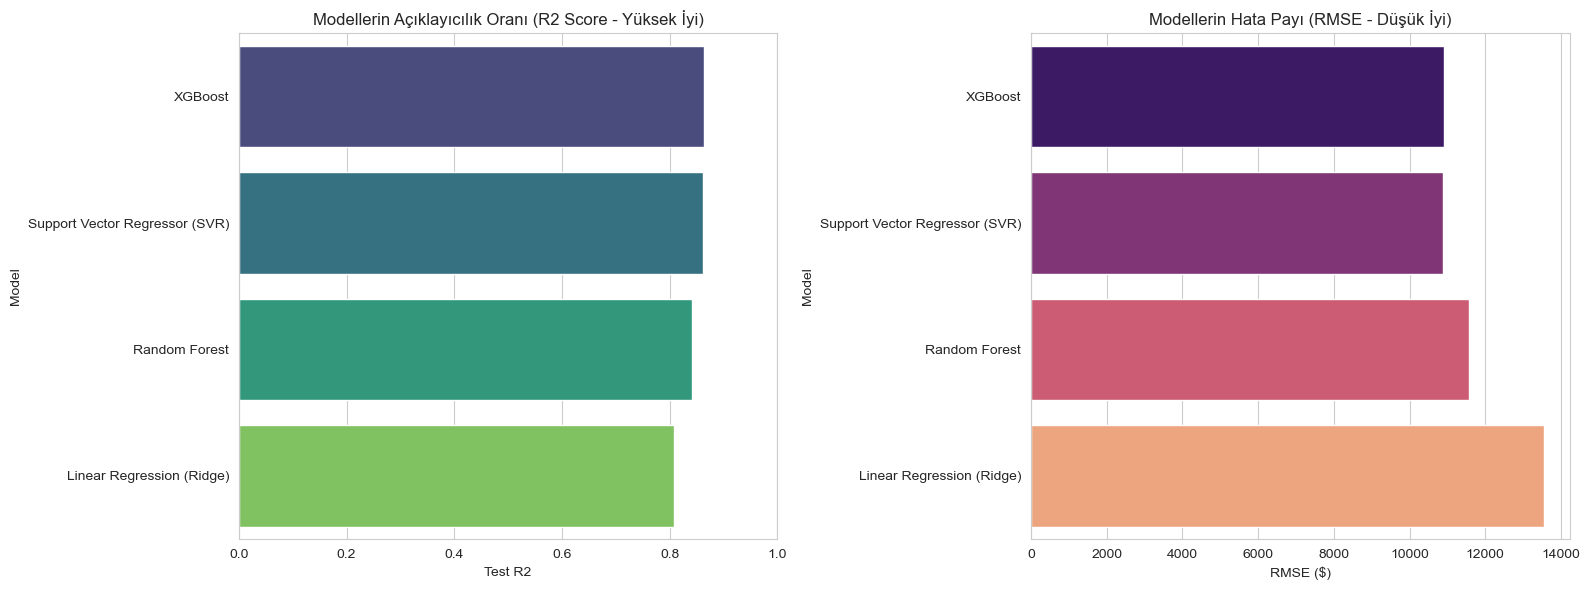

In [6]:
# 6. GÖRSELLEŞTİRME (PERFORMANS GRAFİKLERİ)
# ========================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# R2 Score Karşılaştırması (Başarı Oranı)
sns.barplot(x='Test R2', y='Model', data=df_results, palette='viridis', ax=axes[0])
axes[0].set_title('Modellerin Açıklayıcılık Oranı (R2 Score - Yüksek İyi)')
axes[0].set_xlim(0, 1)

# RMSE Karşılaştırması (Hata Oranı)
sns.barplot(x='RMSE ($)', y='Model', data=df_results, palette='magma', ax=axes[1])
axes[1].set_title('Modellerin Hata Payı (RMSE - Düşük İyi)')

plt.tight_layout()
plt.show()

In [7]:
# ========================================================
# 7. OVERFITTING ANALİZİ VE YORUMU (Proje Maddesi)
# ========================================================
print("\n--- OVERFITTING (AŞIRI ÖĞRENME) ANALİZİ ---")
for index, row in df_results.iterrows():
    diff = row['Train R2'] - row['Test R2']
    print(f"\n{row['Model']}:")
    print(f"  Train Başarısı: %{row['Train R2']*100:.2f}")
    print(f"  Test Başarısı:  %{row['Test R2']*100:.2f}")
    print(f"  Fark: %{diff*100:.2f}")
    
    if diff > 0.10: # %10'dan fazla fark varsa riskli
        print("  DURUM: Overfitting Riski Var!")
        print("  ÇÖZÜM: 'max_depth' azaltıldı, 'Regularization' (alpha/C) artırıldı.")
    else:
        print("  DURUM: Model Dengeli (Genelleme Yapabiliyor).")

# En iyi modeli kaydetme (İleride kullanmak için opsiyonel)
# best_model_overall = models_params[df_results.iloc[0]['Model']]['model'] 
# joblib.dump(best_model_overall, 'best_car_price_model.pkl')


--- OVERFITTING (AŞIRI ÖĞRENME) ANALİZİ ---

XGBoost:
  Train Başarısı: %92.96
  Test Başarısı:  %86.45
  Fark: %6.52
  DURUM: Model Dengeli (Genelleme Yapabiliyor).

Support Vector Regressor (SVR):
  Train Başarısı: %91.94
  Test Başarısı:  %86.20
  Fark: %5.73
  DURUM: Model Dengeli (Genelleme Yapabiliyor).

Random Forest:
  Train Başarısı: %97.89
  Test Başarısı:  %84.16
  Fark: %13.74
  DURUM: Overfitting Riski Var!
  ÇÖZÜM: 'max_depth' azaltıldı, 'Regularization' (alpha/C) artırıldı.

Linear Regression (Ridge):
  Train Başarısı: %81.46
  Test Başarısı:  %80.73
  Fark: %0.73
  DURUM: Model Dengeli (Genelleme Yapabiliyor).
